<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/CDA_Piura_Proyecto_Integrador.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Integrador CDA: El Niño, lluvia y caudales en Piura
**Universidad de Ingeniería y Tecnología — UTEC**  
**Curso:** Ciencia de Datos Ambientales

## Objetivo
Evaluar qué índice ENSO (ONI, ICEN, E o C) se relaciona mejor con la precipitación en Piura y comprobar si la relación cambia entre 1981–1999 y 2000–2024.

Este cuaderno reúne en un solo flujo el área de estudio, la inspección y limpieza de datos, el análisis exploratorio, las hipótesis, un modelamiento inicial y la exportación de resultados. La estructura sigue el estilo de los laboratorios del curso: secciones numeradas, instrucciones breves, código directo con `pandas`, `matplotlib`, series temporales y operaciones espaciales sencillas.

**Nota espacial:** los CSV PISCO que se han identificado tienen una columna cuyo nombre indica `peru_departamento` y, por tanto, representan el polígono del departamento de Piura. No equivalen a la cuenca hidrográfica del río Piura. Para calcular PISCO de la cuenca se necesita el NetCDF/grilla original y el shapefile de la cuenca.


## 1. Paquetes y carpeta de trabajo

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)

CARPETA = '.'
SALIDA = 'RESULTADOS_CDA_PIURA'
os.makedirs(SALIDA, exist_ok=True)

print('Archivos encontrados:')
for archivo in sorted(glob.glob(os.path.join(CARPETA, '*'))):
    if os.path.isfile(archivo):
        print(os.path.basename(archivo))


Archivos encontrados:
% Índice Costero El Niño (ICEN; ENF.txt
% Índice del Niño Oceánico (ONI).txt
% Índices mensuales E y C basados ​.txt
AYABACA.txt
BERNAL.txt
CHULUCANAS.txt
CHUSIS.txt
HACIENDA BIGOTE.txt
HACIENDA SHUMAYA.txt
HUARMACA.txt
LA ESPERANZA.txt
LANCONES.txt
MALLARES.txt
MIRAFLORES.txt
MORROPON.txt
PANANGA.txt
PISCO_PET_V11_DIARIA_1981-2016.csv
PISCO_PET_V11_MENSUAL_1981-2016.csv
PISCO_PP_V21_DIARIA_1981-2016.csv
PISCO_PP_V21_MENSUAL_1981-2016.csv
PISCO_PP_V3_DIARIA_1981-2025.csv
PISCO_PP_V3_MENSUAL_1981-2025.csv
PISCO_TN_V12_DIARIA_1981-2020.csv
PISCO_TN_V12_MENSUAL_1981-2020.csv
PISCO_TX_V12_DIARIA_1981-2020.csv
PISCO_TX_V12_MENSUAL_1981-2020.csv
PORCULLA.txt
SAN MIGUEL.txt
SAN PEDRO.txt
SAPILLICA.txt
SAUSAL DE CULUCAN.txt
SONDORILLO.txt
TULUCE.txt


## 2. Área de estudio: cuenca del río Piura

Coloca en la carpeta el shapefile de la **cuenca hidrográfica del río Piura** y sus archivos auxiliares (`.shp`, `.shx`, `.dbf`, `.prj`, etc.). Cambia el nombre de `archivo_cuenca` para que coincida con tu archivo.

El código revisa la geometría, el sistema de coordenadas, calcula el área aproximada en km² y dibuja el polígono. No se debe usar el límite del departamento como sustituto de la cuenca.

Sistema de coordenadas: EPSG:4326
Unidades disponibles: 18
                           Nombre_UH CODIGO   AREA_KM2
0                    Cuenca Cascajal  13778  3963.3992
1          Unidad Hidrografica 13779  13779  4733.2868
2                     Cuenca Chamaya  49896  8104.9424
3                         Bajo Piura  13781  4746.6714
4                         Alto Piura  13789  1158.2174
5   Cuenca Unidad Hidrografica 13784  13784   918.3314
6                   Medio Alto Piura  13787   508.4975
7           Unidad Hidrografica 1379   1379   918.1398
8                   Medio Bajo Piura  13783  1798.6502
9                      Cuenca Bigote  13788   678.4612
10                   Cuenca Corrales  13786   589.7121
11                       Medio Piura  13785    73.6995
12                 Cuenca La Soledad  13814   598.4188
13                       Alto Quiroz  13869   757.9689
14                     Cuenca Tulman  13866   278.7815
15                 Cuenca Chipillico  13818  1183.5457
16    

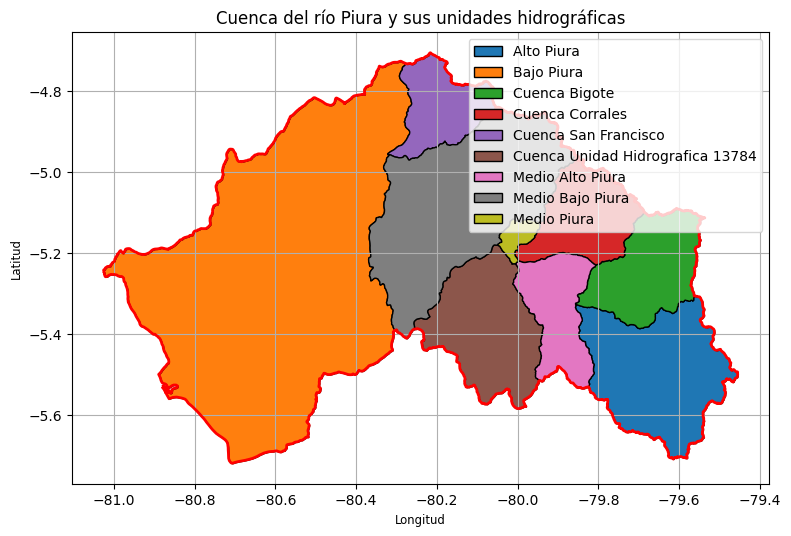

In [ ]:

import geopandas as gpd
import matplotlib.pyplot as plt

archivo_cuenca = 'PIURA_SHU_CUENCA.geojson'

unidades = gpd.read_file(archivo_cuenca)

print('Sistema de coordenadas:', unidades.crs)
print('Unidades disponibles:', len(unidades))
print(unidades[['Nombre_UH', 'CODIGO', 'AREA_KM2']])

# Seleccionar las nueve unidades de la cuenca del río Piura
codigos_piura = [13781, 13782, 13783, 13784, 13785,
                 13786, 13787, 13788, 13789]

unidades_piura = unidades[
    unidades['CODIGO'].astype(int).isin(codigos_piura)
].copy()

# Unir las unidades para formar el área de estudio
cuenca = unidades_piura.dissolve()

print('Unidades seleccionadas:', len(unidades_piura))

# Calcular el área en km²
cuenca_utm = cuenca.to_crs('EPSG:32717')
area_km2 = cuenca_utm.geometry.area.sum() / 1e6

print('Área de estudio (km²):', round(area_km2, 2))

# Mapa de la cuenca completa y sus subunidades
ax = unidades_piura.plot(
    figsize=(9, 9),
    column='Nombre_UH',
    legend=True,
    edgecolor='black'
)

cuenca.boundary.plot(ax=ax, color='red', linewidth=2)

plt.title('Cuenca del río Piura y sus unidades hidrográficas')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.grid()
plt.show()


In [ ]:
import ee
import geemap

# Inicializar Earth Engine
ee.Authenticate()
ee.Initialize(project='utec-ingambiental-01')

# Mapa
#Map = geemap.Map()
Map = geemap.Map(center=[-9.5, -75.0], zoom=7,basemap="Esri.WorldTopoMap")
# 1. Mapa del Perú de fondo: límites departamentales
peru = ee.FeatureCollection('FAO/GAUL/2015/level1') \
    .filter(ee.Filter.eq('ADM0_NAME', 'Peru'))

Map.addLayer(
    peru.style(**{
        'color': '808080',
        'fillColor': 'FFFFFF00',
        'width': 1
    }),
    {},
    'Departamentos del Perú'
)

# 2. Resaltar Piura
piura = peru.filter(ee.Filter.eq('ADM1_NAME', 'Piura'))

Map.addLayer(
    piura.style(**{
        'color': 'D97706',
        'fillColor': 'FDE68A55',
        'width': 2
    }),
    {},
    'Departamento de Piura'
)

# 3. Convertir el GeoDataFrame local (unidades_piura) a ee.FeatureCollection
# Esto evita tener que cargar el archivo manualmente como Asset en Earth Engine
try:
    # 'unidades_piura' es el GeoDataFrame de la sección 2
    cuenca_ee = geemap.gdf_to_ee(unidades_piura)

    Map.addLayer(
        cuenca_ee.style(**{
            'color': 'DC2626',
            'fillColor': '00000000',
            'width': 2
        }),
        {},
        'Unidades hidrográficas de Piura (Local GeoJSON)'
    )
except NameError:
    print("Por favor, ejecuta primero la celda de la sección 2 para definir 'unidades_piura'")

Map.centerObject(piura, 6)
Map

Map(center=[-5.13102061241064, -80.33388961471441], controls=(WidgetControl(options=['position', 'transparent_…

## 3. Estaciones SENAMHI: carga e inspección

In [ ]:
archivos_estaciones = [
    a for a in glob.glob(os.path.join(CARPETA, '*.txt'))
    if os.path.basename(a).upper() in [
        'PORCULLA.TXT', 'SAN MIGUEL.TXT', 'SAN PEDRO.TXT',
        'SAPILLICA.TXT', 'SAUSAL DE CULUCAN.TXT', 'SONDORILLO.TXT',
        'TULUCE.TXT'
    ]
]

In [ ]:

archivos_txt = glob.glob(os.path.join(CARPETA, '*.txt'))

archivos_indices = [
    a for a in archivos_txt
    if os.path.basename(a).startswith('%')
]

archivos_estaciones = [
    a for a in archivos_txt
    if not os.path.basename(a).startswith('%')
]

print('Estaciones encontradas:', len(archivos_estaciones))
print('Índices ENSO encontrados:', len(archivos_indices))
print([os.path.basename(a) for a in archivos_estaciones])

columnas = ['anio', 'mes', 'dia', 'pp_mm', 'tmax_c', 'tmin_c']
lista_estaciones = []

for archivo in archivos_estaciones:
    datos = pd.read_csv(
        archivo, sep=r'\s+', header=None, names=columnas,
        usecols=range(6), engine='python'
    )

    datos['estacion'] = os.path.splitext(
        os.path.basename(archivo)
    )[0]

    lista_estaciones.append(datos)

estaciones = pd.concat(lista_estaciones, ignore_index=True)

estaciones['fecha'] = pd.to_datetime(
    dict(
        year=estaciones['anio'],
        month=estaciones['mes'],
        day=estaciones['dia']
    ),
    errors='coerce'
)

estaciones = estaciones.replace([-99.9, -999, -9999, -99], np.nan)
estaciones = estaciones.sort_values(['estacion', 'fecha'])

print('Registros:', len(estaciones))
print('Estaciones:', estaciones['estacion'].nunique())
display(estaciones.head())


Estaciones encontradas: 20
Índices ENSO encontrados: 3
['PORCULLA.txt', 'MORROPON.txt', 'SONDORILLO.txt', 'SAN MIGUEL.txt', 'LA ESPERANZA.txt', 'BERNAL.txt', 'MALLARES.txt', 'SAPILLICA.txt', 'SAN PEDRO.txt', 'HACIENDA BIGOTE.txt', 'LANCONES.txt', 'MIRAFLORES.txt', 'CHUSIS.txt', 'TULUCE.txt', 'AYABACA.txt', 'HACIENDA SHUMAYA.txt', 'PANANGA.txt', 'SAUSAL DE CULUCAN.txt', 'HUARMACA.txt', 'CHULUCANAS.txt']
Registros: 357524
Estaciones: 20


,anio,mes,dia,pp_mm,tmax_c,tmin_c,estacion,fecha
248731,1963,1,1,0.0,21.0,6.0,AYABACA,1963-01-01
248732,1963,1,2,0.0,21.0,6.0,AYABACA,1963-01-02
248733,1963,1,3,0.0,21.0,8.0,AYABACA,1963-01-03
248734,1963,1,4,0.0,21.5,6.0,AYABACA,1963-01-04
248735,1963,1,5,0.0,21.5,6.5,AYABACA,1963-01-05


In [ ]:
if len(estaciones) > 0:
    print('Fechas inválidas:', estaciones['fecha'].isna().sum())
    print('Duplicados estación-fecha:', estaciones.duplicated(['estacion', 'fecha']).sum())
    print('Precipitación negativa:', (estaciones['pp_mm'] < 0).sum())
    display(estaciones.isna().sum())

    resumen_estaciones = estaciones.groupby('estacion').agg(
        registros=('fecha', 'count'),
        inicio=('fecha', 'min'),
        fin=('fecha', 'max'),
        faltantes_pp=('pp_mm', lambda x: x.isna().sum()),
        pp_max=('pp_mm', 'max')
    ).reset_index()
    display(resumen_estaciones)
    resumen_estaciones.to_csv(os.path.join(SALIDA, '01_resumen_estaciones.csv'), index=False)


Fechas inválidas: 0
Duplicados estación-fecha: 0
Precipitación negativa: 0


,0
anio,0
mes,0
dia,0
pp_mm,21249
tmax_c,182288
tmin_c,183101
estacion,0
fecha,0


,estacion,registros,inicio,fin,faltantes_pp,pp_max
0,AYABACA,18809,1963-01-01,2014-06-30,674,124.3
1,BERNAL,18505,1963-11-01,2014-06-30,1101,123.2
2,CHULUCANAS,15521,1972-01-02,2014-06-30,2873,202.5
3,CHUSIS,18441,1963-11-04,2014-04-30,2594,136.2
4,HACIENDA BIGOTE,18294,1963-12-01,2013-12-31,1061,240.0
5,HACIENDA SHUMAYA,18324,1963-11-01,2013-12-31,393,100.8
6,HUARMACA,19006,1963-10-19,2015-10-31,705,145.2
7,LA ESPERANZA,18020,1966-07-01,2015-10-31,869,134.8
8,LANCONES,18566,1963-09-01,2014-06-30,489,193.8
9,MALLARES,19539,1961-01-01,2014-06-30,4271,201.0


### 3.1 Limpieza de estaciones y precipitación mensual

,estacion,fecha,pp_mm
261926,AYABACA,1999-02-16,124.3
266300,AYABACA,2011-02-07,90.7
256103,AYABACA,1983-03-09,78.1
101283,BERNAL,1998-02-18,123.2
101303,BERNAL,1998-03-10,108.4
101316,BERNAL,1998-03-23,79.8
346045,CHULUCANAS,1983-01-26,202.5
346159,CHULUCANAS,1983-05-20,180.1
346054,CHULUCANAS,1983-02-04,167.2
219014,CHUSIS,1983-03-23,136.2


,estacion,fecha,pp_mensual_mm,dias_validos
0,AYABACA,1963-01-01,85.21,31
1,AYABACA,1963-02-01,137.01,28
2,AYABACA,1963-03-01,405.01,31
3,AYABACA,1963-04-01,133.01,30
4,AYABACA,1963-05-01,86.00,31


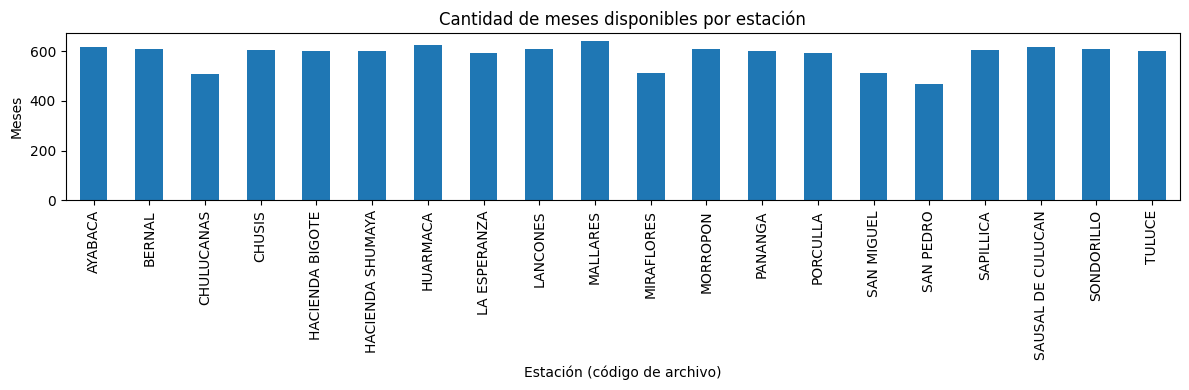

In [ ]:
if len(estaciones) > 0:
    estaciones = estaciones.dropna(subset=['fecha'])
    estaciones = estaciones.drop_duplicates(['estacion', 'fecha'], keep='first')
    estaciones.loc[estaciones['pp_mm'] < 0, 'pp_mm'] = np.nan

    # Los extremos se conservan; se muestran para revisión, no se eliminan automáticamente.
    extremos = estaciones.sort_values('pp_mm', ascending=False).groupby('estacion').head(3)
    display(extremos[['estacion', 'fecha', 'pp_mm']].sort_values(['estacion', 'pp_mm'], ascending=[True, False]))
    extremos.to_csv(os.path.join(SALIDA, '02_extremos_estaciones.csv'), index=False)

    estaciones['mes_fecha'] = estaciones['fecha'].dt.to_period('M').dt.to_timestamp()
    mensual_estaciones = estaciones.groupby(['estacion', 'mes_fecha']).agg(
        pp_mensual_mm=('pp_mm', lambda x: x.sum(min_count=1)),
        dias_validos=('pp_mm', 'count')
    ).reset_index().rename(columns={'mes_fecha': 'fecha'})
    display(mensual_estaciones.head())
    mensual_estaciones.to_csv(os.path.join(SALIDA, '03_estaciones_mensuales.csv'), index=False)

    mensual_estaciones.groupby('estacion').size().plot(kind='bar', figsize=(12, 4))
    plt.title('Cantidad de meses disponibles por estación')
    plt.ylabel('Meses')
    plt.xlabel('Estación (código de archivo)')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


Estaciones dentro del poligono: 8


,estacion,latitud,longitud
0,HUARMACA,-5.565861,-79.525444
1,MORROPON,-5.194644,-79.971075
2,CHULUCANAS,-5.108444,-80.169539
3,MIRAFLORES,-5.175278,-80.616542
4,SAN MIGUEL,-5.246186,-80.684250
5,CHUSIS,-5.516944,-80.833611
6,HACIENDA BIGOTE,-5.320889,-79.785686
8,SAN PEDRO,-5.079536,-80.016214


Registros diarios: 135302
Estaciones: ['CHULUCANAS', 'CHUSIS', 'HACIENDA BIGOTE', 'HUARMACA', 'MIRAFLORES', 'MORROPON', 'SAN MIGUEL', 'SAN PEDRO']


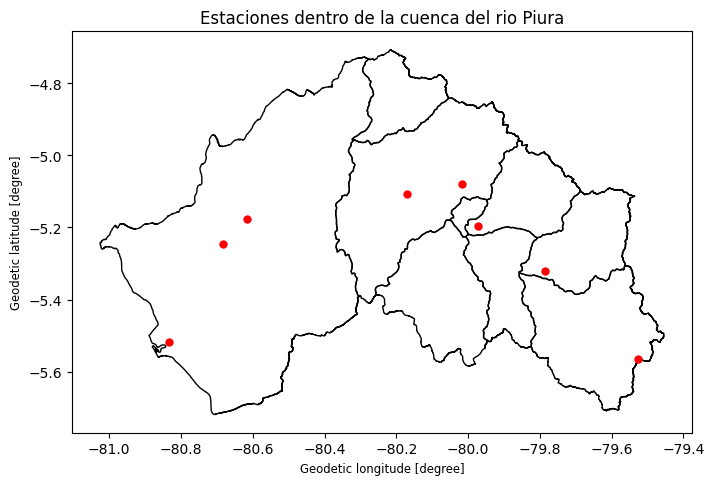

In [ ]:

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# Coordenadas de las estaciones consultadas en SENAMHI
coordenadas = pd.DataFrame({
    'estacion': [
        'HUARMACA', 'MORROPON', 'CHULUCANAS',
        'MIRAFLORES', 'SAN MIGUEL', 'CHUSIS',
        'HACIENDA BIGOTE', 'HACIENDA SHUMAYA',
        'SAN PEDRO'
    ],
    'latitud': [
        -5.565861, -5.194644, -5.108444,
        -5.175278, -5.246186, -5.516944,
        -5.320889, -5.364919, -5.079536
    ],
    'longitud': [
        -79.525444, -79.971075, -80.169539,
        -80.616542, -80.684250, -80.833611,
        -79.785686, -79.359931, -80.016214
    ]
})

# Leer el poligono de la cuenca
cuenca = gpd.read_file(
    os.path.join(CARPETA, 'PIURA_SHU_CUENCA.geojson')
)

if cuenca.crs is None:
    raise ValueError('El poligono no tiene CRS definido.')

cuenca = cuenca.to_crs('EPSG:4326')

# Crear puntos de las estaciones
puntos = gpd.GeoDataFrame(
    coordenadas,
    geometry=gpd.points_from_xy(
        coordenadas['longitud'],
        coordenadas['latitud']
    ),
    crs='EPSG:4326'
)

# Seleccionar puntos dentro de la cuenca
seleccion = gpd.sjoin(
    puntos,
    cuenca[['geometry']],
    how='inner',
    predicate='within'
)

print('Estaciones dentro del poligono:', len(seleccion))
display(seleccion[['estacion', 'latitud', 'longitud']])

# Filtrar los registros diarios de esas estaciones
nombres = seleccion['estacion'].tolist()

estaciones_cuenca = estaciones[
    estaciones['estacion'].isin(nombres)
].copy()

print('Registros diarios:', len(estaciones_cuenca))
print('Estaciones:', sorted(estaciones_cuenca['estacion'].unique()))

# Mapa de verificacion
ax = cuenca.plot(
    figsize=(8, 8),
    facecolor='none',
    edgecolor='black'
)
seleccion.plot(ax=ax, color='red', markersize=25)

plt.title('Estaciones dentro de la cuenca del rio Piura')
plt.show()

# Guardar los datos filtrados
estaciones_cuenca.to_csv(
    os.path.join(CARPETA, 'estaciones_cuenca_piura.csv'),
    index=False
)


## 4. PISCO diario y mensual

Los CSV que se encontraron se llaman `PISCO_PP_V3_DIARIA_1981-2025.csv` y `PISCO_PP_V3_MENSUAL_1981-2025.csv`. La primera columna es la fecha y la segunda contiene la precipitación. El nombre de la columna indica un polígono de departamento, así que revisamos el dato y documentamos esa limitación.

In [ ]:
archivo_pisco_diario = 'PISCO_PP_V3_DIARIA_1981-2025.csv'
archivo_pisco_mensual = 'PISCO_PP_V3_MENSUAL_1981-2025.csv'

def cargar_pisco(archivo):
    datos = pd.read_csv(archivo)
    datos.columns = datos.columns.str.strip()
    datos = datos.rename(columns={datos.columns[0]: 'fecha', datos.columns[1]: 'pp_mm'})
    datos['fecha'] = pd.to_datetime(datos['fecha'], errors='coerce')
    datos['pp_mm'] = pd.to_numeric(datos['pp_mm'], errors='coerce')
    datos = datos.dropna(subset=['fecha']).sort_values('fecha')
    return datos

if os.path.exists(archivo_pisco_diario):
    pisco_diario = cargar_pisco(archivo_pisco_diario)
    print('PISCO diario:', pisco_diario.shape)
    print('Periodo:', pisco_diario['fecha'].min(), 'a', pisco_diario['fecha'].max())
    print('Fechas duplicadas:', pisco_diario['fecha'].duplicated().sum())
    print('Faltantes:', pisco_diario['pp_mm'].isna().sum())
    print('Valores negativos:', (pisco_diario['pp_mm'] < 0).sum())
    display(pisco_diario.head())
else:
    pisco_diario = pd.DataFrame()
    print('No se encontró:', archivo_pisco_diario)


PISCO diario: (16436, 2)
Periodo: 1981-01-01 00:00:00 a 2025-12-31 00:00:00
Fechas duplicadas: 0
Faltantes: 0
Valores negativos: 0


,fecha,pp_mm
0,1981-01-01,0.129817
1,1981-01-02,0.770193
2,1981-01-03,0.261180
3,1981-01-04,0.022761
4,1981-01-05,0.003801


In [ ]:
if os.path.exists(archivo_pisco_mensual):
    pisco_mensual = cargar_pisco(archivo_pisco_mensual)
    print('PISCO mensual:', pisco_mensual.shape)
    print('Periodo:', pisco_mensual['fecha'].min(), 'a', pisco_mensual['fecha'].max())
    print('Fechas duplicadas:', pisco_mensual['fecha'].duplicated().sum())
    display(pisco_mensual.head())
else:
    pisco_mensual = pd.DataFrame()
    print('No se encontró:', archivo_pisco_mensual)


PISCO mensual: (540, 2)
Periodo: 1981-01-01 00:00:00 a 2025-12-01 00:00:00
Fechas duplicadas: 0


,fecha,pp_mm
0,1981-01-01,13.123163
1,1981-02-01,38.229765
2,1981-03-01,122.923211
3,1981-04-01,24.314943
4,1981-05-01,7.905679


### 4.1 Comparar PISCO diario y mensual

Meses comparables: 540


,fecha,pp_diaria_acum,pp_mensual_archivo
0,1981-01-01,13.123163,13.123163
1,1981-02-01,38.229765,38.229765
2,1981-03-01,122.923211,122.923211
3,1981-04-01,24.314943,24.314943
4,1981-05-01,7.905679,7.905679


Correlación: 1.0


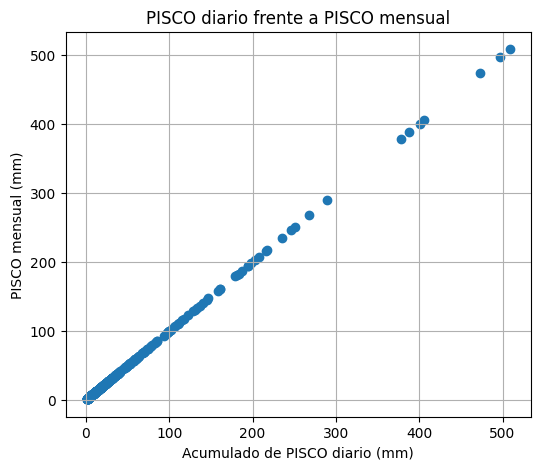

In [ ]:
if len(pisco_diario) > 0:
    pisco_diario = pisco_diario.drop_duplicates('fecha', keep='first')
    pisco_diario.loc[pisco_diario['pp_mm'] < 0, 'pp_mm'] = np.nan
    pisco_diario['mes_fecha'] = pisco_diario['fecha'].dt.to_period('M').dt.to_timestamp()
    suma_diaria = pisco_diario.groupby('mes_fecha')['pp_mm'].sum(min_count=1).reset_index()
    suma_diaria = suma_diaria.rename(columns={'mes_fecha': 'fecha', 'pp_mm': 'pp_diaria_acum'})

    if len(pisco_mensual) > 0:
        comparacion_pisco = suma_diaria.merge(pisco_mensual, on='fecha', how='inner', suffixes=('_diaria', '_mensual'))
        comparacion_pisco = comparacion_pisco.rename(columns={'pp_mm': 'pp_mensual_archivo'})
        print('Meses comparables:', len(comparacion_pisco))
        display(comparacion_pisco.head())
        if len(comparacion_pisco) > 0:
            print('Correlación:', comparacion_pisco['pp_diaria_acum'].corr(comparacion_pisco['pp_mensual_archivo']))
            plt.figure(figsize=(6, 5))
            plt.scatter(comparacion_pisco['pp_diaria_acum'], comparacion_pisco['pp_mensual_archivo'])
            plt.xlabel('Acumulado de PISCO diario (mm)')
            plt.ylabel('PISCO mensual (mm)')
            plt.title('PISCO diario frente a PISCO mensual')
            plt.grid()
            plt.show()


## 5. Índices ENSO: ICEN, ONI, E y C

Se utilizan los archivos TXT originales. ICEN y E/C tienen año y mes; ONI está en trimestres móviles (DJF, JFM, etc.). Para una comparación mensual exploratoria, asignamos ONI al mes central del trimestre y dejamos esa decisión documentada.

In [ ]:
archivo_icen = glob.glob('*ICEN*.txt')
archivo_oni = glob.glob('*ONI*.txt')
archivo_ec = glob.glob('*E*y*C*.txt')

print('ICEN:', [os.path.basename(x) for x in archivo_icen])
print('ONI:', [os.path.basename(x) for x in archivo_oni])
print('E/C:', [os.path.basename(x) for x in archivo_ec])


ICEN: ['% Índice Costero El Niño (ICEN; ENF.txt']
ONI: ['% Índice del Niño Oceánico (ONI).txt']
E/C: ['% Índices mensuales E y C basados \u200b.txt']


In [ ]:
if archivo_icen:
    icen = pd.read_csv(archivo_icen[0], sep=r'\s+', comment='%', header=None,
                       names=['anio', 'mes', 'ICEN'])
    icen['ICEN'] = icen['ICEN'].astype(str).str.replace(',', '.', regex=False)
    icen['ICEN'] = pd.to_numeric(icen['ICEN'], errors='coerce')
    icen['fecha'] = pd.to_datetime(dict(year=icen['anio'], month=icen['mes'], day=1), errors='coerce')
    icen = icen[['fecha', 'ICEN']].dropna(subset=['fecha']).sort_values('fecha')
    icen = icen.drop_duplicates('fecha', keep='first')
    print('ICEN:', icen.shape, icen['fecha'].min(), icen['fecha'].max())
    display(icen.head())
else:
    icen = pd.DataFrame(columns=['fecha', 'ICEN'])
    print('No se encontró el TXT de ICEN.')


ICEN: (918, 2) 1950-01-01 00:00:00 2026-07-01 00:00:00


,fecha,ICEN
0,1950-01-01,-0.75
1,1950-02-01,-1.07
2,1950-03-01,-1.25
3,1950-04-01,-1.18
4,1950-05-01,-1.22


In [ ]:
mes_central = {'DJF': 1, 'JFM': 2, 'FMA': 3, 'MAM': 4, 'AMJ': 5, 'MJJ': 6,
               'JJA': 7, 'JAS': 8, 'ASO': 9, 'SON': 10, 'OND': 11, 'NDJ': 12}

if archivo_oni:
    oni = pd.read_csv(archivo_oni[0], sep=r'\s+', comment='%', skiprows=1, header=None,
                      names=['trimestre', 'anio', 'total', 'ONI'])
    oni['ONI'] = pd.to_numeric(oni['ONI'], errors='coerce')
    oni['mes'] = oni['trimestre'].astype(str).str.strip().map(mes_central)
    oni['fecha'] = pd.to_datetime(dict(year=oni['anio'], month=oni['mes'], day=1), errors='coerce')
    oni = oni[['fecha', 'ONI']].dropna(subset=['fecha']).sort_values('fecha')
    oni = oni.drop_duplicates('fecha', keep='first')
    print('ONI:', oni.shape, oni['fecha'].min(), oni['fecha'].max())
    display(oni.head())
else:
    oni = pd.DataFrame(columns=['fecha', 'ONI'])
    print('No se encontró el TXT de ONI.')


ONI: (904, 2) 1950-01-01 00:00:00 2026-08-01 00:00:00


,fecha,ONI
1,1950-01-01,-1.32
2,1950-02-01,-1.20
3,1950-03-01,-1.12
4,1950-04-01,-1.08
5,1950-05-01,-1.10


In [ ]:
if archivo_ec:
    ec = pd.read_csv(archivo_ec[0], sep=r'\s+', comment='%', header=None, names=['anio', 'mes', 'E', 'C'])
    for columna in ['E', 'C']:
        ec[columna] = ec[columna].astype(str).str.replace(',', '.', regex=False)
        ec[columna] = pd.to_numeric(ec[columna], errors='coerce')
    ec['fecha'] = pd.to_datetime(dict(year=ec['anio'], month=ec['mes'], day=1), errors='coerce')
    ec = ec[['fecha', 'E', 'C']].dropna(subset=['fecha']).sort_values('fecha')
    ec = ec.drop_duplicates('fecha', keep='first')
    print('E/C:', ec.shape, ec['fecha'].min(), ec['fecha'].max())
    display(ec.head())
else:
    ec = pd.DataFrame(columns=['fecha', 'E', 'C'])
    print('No se encontró el TXT de E y C.')


E/C: (1682, 3) 1880-01-01 00:00:00 2020-02-01 00:00:00


,fecha,E,C
0,1880-01-01,-1.243070,-1.20191
1,1880-02-01,-0.774297,-1.31261
2,1880-03-01,0.335610,-1.68796
3,1880-04-01,0.636913,-1.76129
4,1880-05-01,0.279847,-1.51977


### 5.1 Integrar los índices por fecha mensual

Periodo de índices: 1880-01-01 00:00:00 a 2026-08-01 00:00:00


,0
fecha,0
ICEN,842
ONI,1125
E,78
C,78


,fecha,ICEN,ONI,E,C
0,1880-01-01,NaN,NaN,-1.243070,-1.20191
1,1880-02-01,NaN,NaN,-0.774297,-1.31261
2,1880-03-01,NaN,NaN,0.335610,-1.68796
3,1880-04-01,NaN,NaN,0.636913,-1.76129
4,1880-05-01,NaN,NaN,0.279847,-1.51977


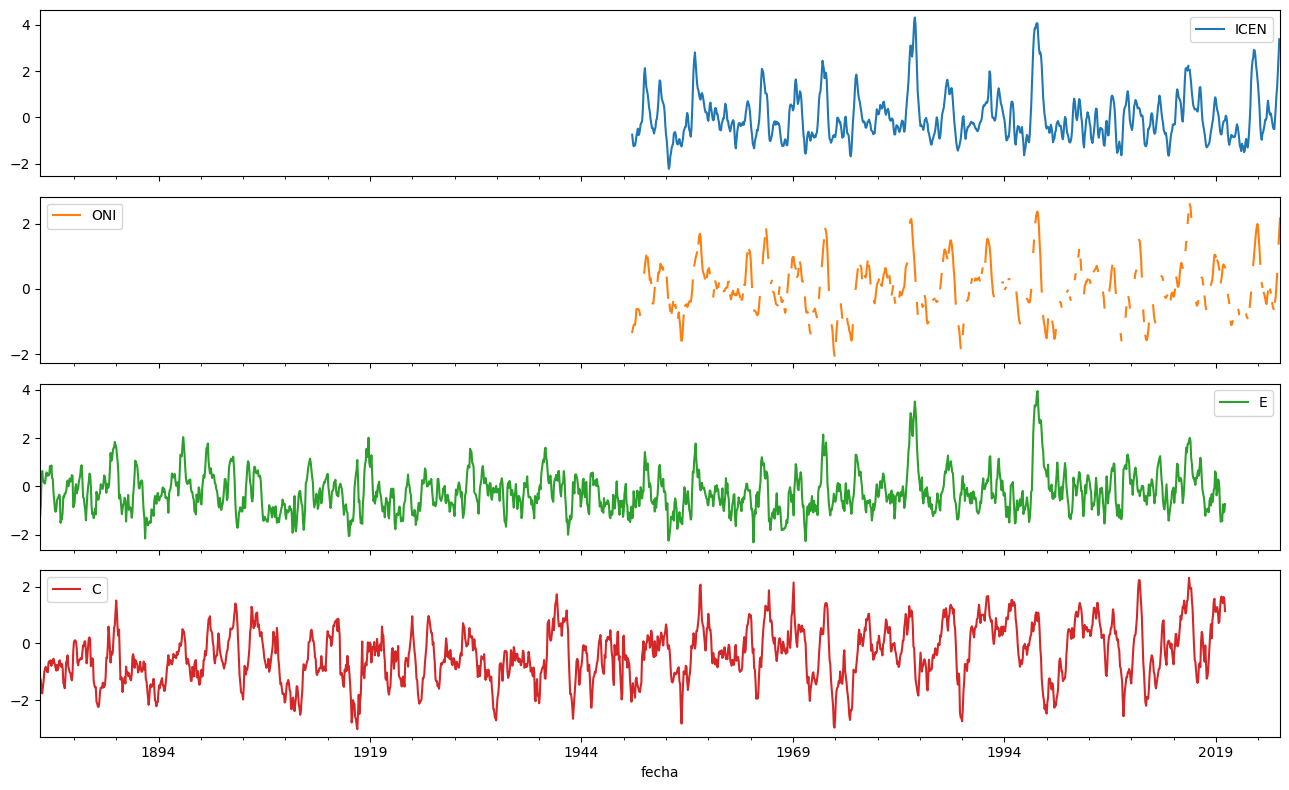

In [ ]:
indices = icen.merge(oni, on='fecha', how='outer').merge(ec, on='fecha', how='outer')
indices = indices.sort_values('fecha').drop_duplicates('fecha')
print('Periodo de índices:', indices['fecha'].min(), 'a', indices['fecha'].max())
display(indices.isna().sum())
display(indices.head())
indices.to_csv(os.path.join(SALIDA, '04_indices_enso_limpios.csv'), index=False)

indices.set_index('fecha')[['ICEN', 'ONI', 'E', 'C']].plot(subplots=True, figsize=(13, 8), sharex=True)
plt.tight_layout()
plt.show()


## 6. Análisis exploratorio: estacionalidad y extremos

Primero observamos la precipitación mensual y anual. Los valores extremos se conservan porque son relevantes para el estudio de El Niño. El percentil 95 se usa como umbral exploratorio de lluvia extrema; se puede cambiar si el equipo justifica otro criterio.

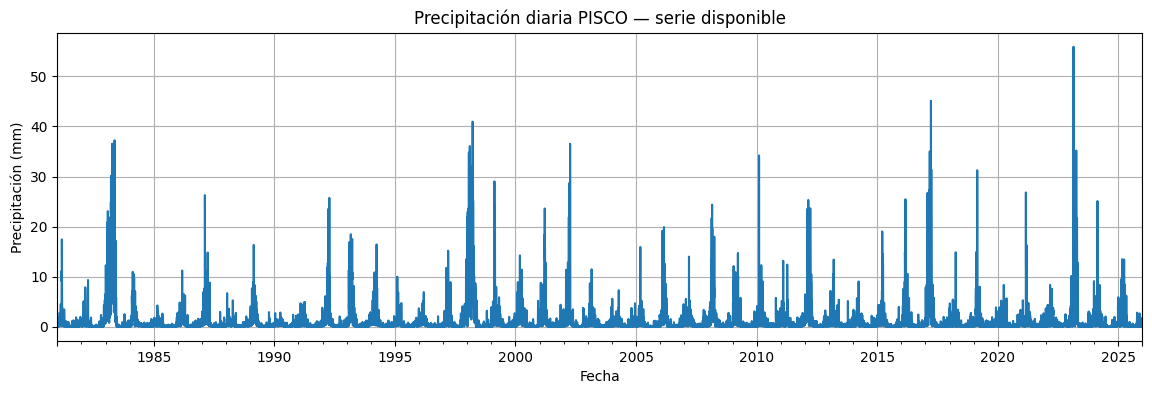

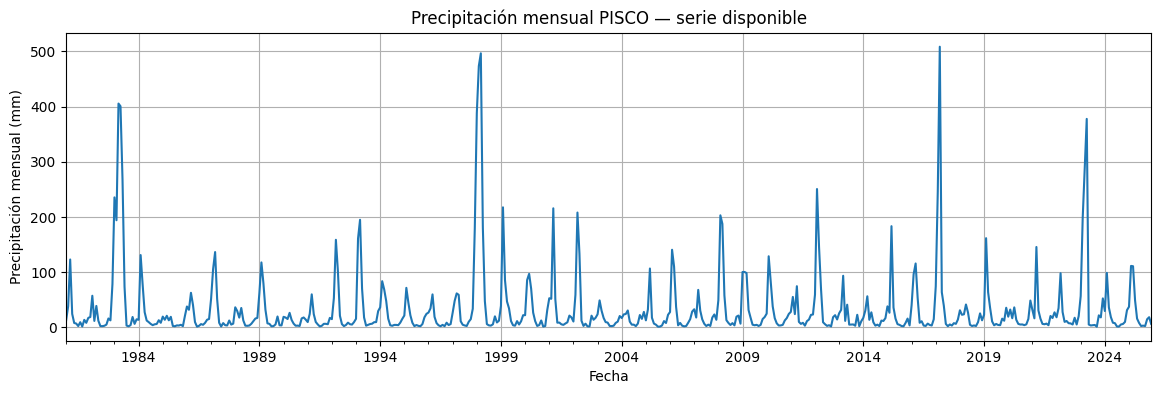

In [ ]:
if len(pisco_diario) > 0:
    pisco_diario = pisco_diario.sort_values('fecha')
    pisco_diario.set_index('fecha')['pp_mm'].plot(figsize=(14, 4))
    plt.title('Precipitación diaria PISCO — serie disponible')
    plt.xlabel('Fecha')
    plt.ylabel('Precipitación (mm)')
    plt.grid()
    plt.show()

if len(pisco_mensual) > 0:
    pisco_mensual = pisco_mensual.sort_values('fecha')
    pisco_mensual.set_index('fecha')['pp_mm'].plot(figsize=(14, 4))
    plt.title('Precipitación mensual PISCO — serie disponible')
    plt.xlabel('Fecha')
    plt.ylabel('Precipitación mensual (mm)')
    plt.grid()
    plt.show()


Umbral exploratorio P95 (mm/día): 5.051


,anio,pp_anual_mm,dias_extremos,pp_max_diaria
0,1981,265.355835,9,17.429018
1,1982,257.699399,9,9.329600
2,1983,1625.552521,117,37.225857
3,1984,313.999394,12,10.958418
4,1985,124.646147,0,4.243424


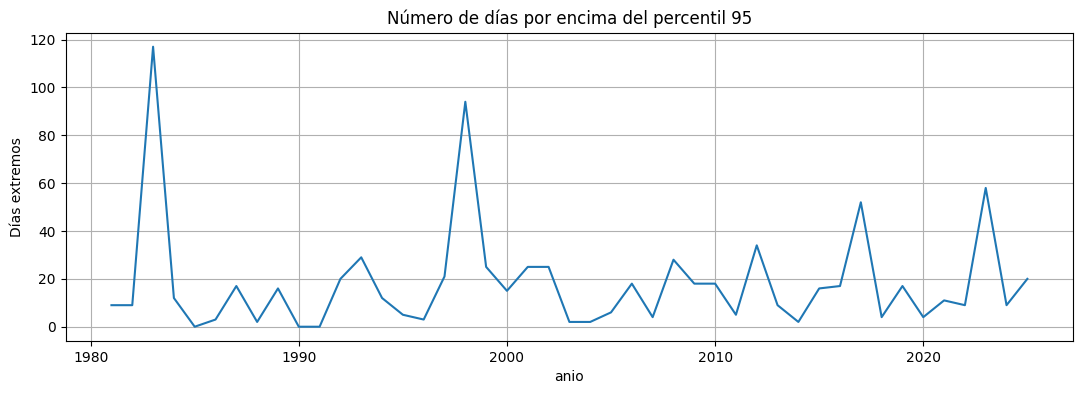

In [ ]:
if len(pisco_diario) > 0:
    umbral_extremo = pisco_diario['pp_mm'].quantile(0.95)
    pisco_diario['lluvia_extrema'] = pisco_diario['pp_mm'] > umbral_extremo
    pisco_diario['anio'] = pisco_diario['fecha'].dt.year
    extremos_anuales = pisco_diario.groupby('anio').agg(
        pp_anual_mm=('pp_mm', lambda x: x.sum(min_count=1)),
        dias_extremos=('lluvia_extrema', 'sum'),
        pp_max_diaria=('pp_mm', 'max')
    ).reset_index()
    print('Umbral exploratorio P95 (mm/día):', round(umbral_extremo, 3))
    display(extremos_anuales.head())
    extremos_anuales.to_csv(os.path.join(SALIDA, '05_indicadores_anuales_pisco.csv'), index=False)

    extremos_anuales.plot(x='anio', y='dias_extremos', figsize=(13, 4), legend=False)
    plt.title('Número de días por encima del percentil 95')
    plt.ylabel('Días extremos')
    plt.grid()
    plt.show()


### 6.1 Temporada húmeda (diciembre–mayo)

,anio,pp_dic_may_mm
0,1981,NaN
1,1982,155.375611
2,1983,1581.718412
3,1984,276.198719
4,1985,94.084226


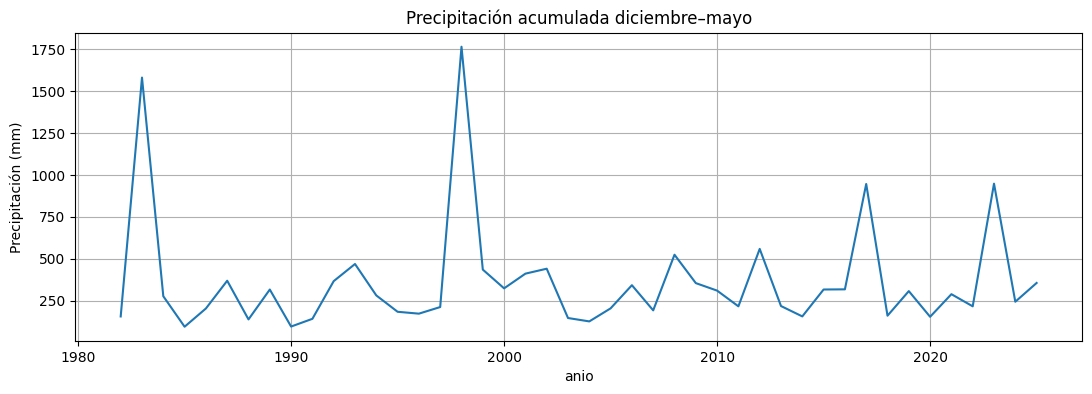

In [ ]:
if len(pisco_mensual) > 0:
    pisco_mensual['anio'] = pisco_mensual['fecha'].dt.year
    pisco_mensual['mes'] = pisco_mensual['fecha'].dt.month
    pisco_mensual['anio_temporada'] = np.where(
        pisco_mensual['mes'] == 12, pisco_mensual['anio'] + 1, pisco_mensual['anio']
    )
    temporada = pisco_mensual[pisco_mensual['mes'].isin([12, 1, 2, 3, 4, 5])]
    lluvia_temporada = temporada.groupby('anio_temporada')['pp_mm'].sum(min_count=6).reset_index()
    lluvia_temporada = lluvia_temporada.rename(columns={
        'anio_temporada': 'anio', 'pp_mm': 'pp_dic_may_mm'
    })
    display(lluvia_temporada.head())
    lluvia_temporada.to_csv(os.path.join(SALIDA, '06_lluvia_temporada_humeda.csv'), index=False)

    lluvia_temporada.plot(x='anio', y='pp_dic_may_mm', figsize=(13, 4), legend=False)
    plt.title('Precipitación acumulada diciembre–mayo')
    plt.ylabel('Precipitación (mm)')
    plt.grid()
    plt.show()


## 7. Relación entre precipitación e índices ENSO

Integramos por mes las series disponibles. Las correlaciones son exploratorias: no prueban causalidad. ONI es un promedio trimestral móvil asignado al mes central, por lo que esa convención debe tenerse en cuenta.

,fecha,pp_mm,ICEN,ONI,E,C
0,1981-01-01,13.123163,-0.74,-0.27,-1.331200,0.015859
1,1981-02-01,38.229765,-0.74,-0.42,-1.070690,-0.231930
2,1981-03-01,122.923211,-0.48,NaN,-0.431558,-0.341991
3,1981-04-01,24.314943,-0.34,-0.27,-0.374029,-0.502532
4,1981-05-01,7.905679,-0.38,NaN,-0.290326,-0.733554


Correlaciones con precipitación mensual:


,pp_mm
pp_mm,1.000000
E,0.385352
ICEN,0.346710
ONI,0.212170
C,-0.019712


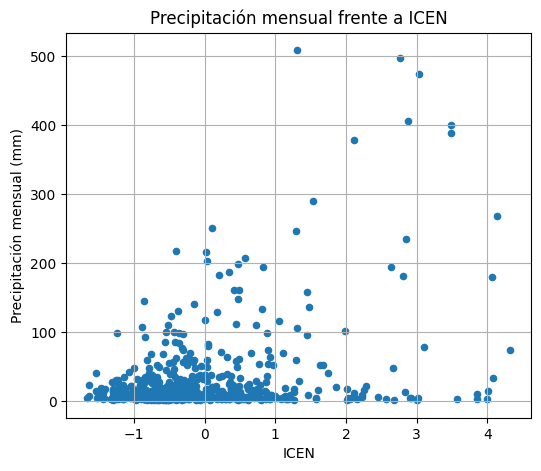

In [ ]:
if len(pisco_mensual) > 0:
    lluvia = pisco_mensual[['fecha', 'pp_mm']].drop_duplicates('fecha').copy()
    base_mensual = lluvia.merge(indices, on='fecha', how='left')
    base_mensual = base_mensual.sort_values('fecha')
    display(base_mensual.head())
    print('Correlaciones con precipitación mensual:')
    display(base_mensual[['pp_mm', 'ICEN', 'ONI', 'E', 'C']].corr()['pp_mm'].sort_values(ascending=False))
    base_mensual.to_csv(os.path.join(SALIDA, '07_base_mensual_pisco_enso.csv'), index=False)

    base_mensual.plot.scatter(x='ICEN', y='pp_mm', figsize=(6, 5))
    plt.title('Precipitación mensual frente a ICEN')
    plt.xlabel('ICEN')
    plt.ylabel('Precipitación mensual (mm)')
    plt.grid()
    plt.show()
else:
    base_mensual = pd.DataFrame()
    print('No hay PISCO mensual para integrar.')


### 7.1 Comparar los periodos 1981–1999 y 2000–2024

In [ ]:
if len(base_mensual) > 0:
    base_mensual['periodo'] = np.where(base_mensual['fecha'].dt.year <= 1999,
                                       '1981–1999', '2000–2024')
    correlaciones_periodo = base_mensual.groupby('periodo')[['pp_mm', 'ICEN', 'ONI', 'E', 'C']].corr()
    display(correlaciones_periodo)
    correlaciones_periodo.to_csv(os.path.join(SALIDA, '08_correlaciones_por_periodo.csv'))


pp_mm      ICEN       ONI         E         C
periodo                                                          
1981–1999 pp_mm  1.000000  0.447724  0.366301  0.462176  0.104080
          ICEN   0.447724  1.000000  0.746842  0.945153  0.297374
          ONI    0.366301  0.746842  1.000000  0.620430  0.836698
          E      0.462176  0.945153  0.620430  1.000000  0.078782
          C      0.104080  0.297374  0.836698  0.078782  1.000000
2000–2024 pp_mm  1.000000  0.202128 -0.057348  0.221902 -0.177180
          ICEN   0.202128  1.000000  0.705546  0.849849  0.330619
          ONI   -0.057348  0.705546  1.000000  0.419597  0.903276
          E      0.221902  0.849849  0.419597  1.000000 -0.013085
          C     -0.177180  0.330619  0.903276 -0.013085  1.000000

## 8. Modelamiento inicial y evaluación temporal

Como primera comparación se ajusta una regresión lineal para estimar precipitación mensual usando cada índice por separado. La evaluación usa los años más recientes como conjunto de prueba, evitando una división aleatoria que mezcle pasado y futuro. Esto es una línea base; después se puede comparar con Random Forest y clasificación de temporadas extremas.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

resultados_modelos = []

if len(base_mensual) > 0:
    datos_modelo = base_mensual.dropna(subset=['pp_mm']).copy()
    datos_modelo = datos_modelo[datos_modelo['fecha'].dt.year <= 2024]

    for indice in ['ONI', 'ICEN', 'E', 'C']:
        datos_indice = datos_modelo.dropna(subset=[indice]).sort_values('fecha')
        if len(datos_indice) >= 60:
            corte = int(len(datos_indice) * 0.8)
            entrenamiento = datos_indice.iloc[:corte]
            prueba = datos_indice.iloc[corte:]

            modelo = LinearRegression()
            modelo.fit(entrenamiento[[indice]], entrenamiento['pp_mm'])
            prediccion = modelo.predict(prueba[[indice]])

            resultados_modelos.append({
                'indice': indice,
                'n_entrenamiento': len(entrenamiento),
                'n_prueba': len(prueba),
                'R2': r2_score(prueba['pp_mm'], prediccion),
                'RMSE': mean_squared_error(prueba['pp_mm'], prediccion) ** 0.5,
                'MAE': mean_absolute_error(prueba['pp_mm'], prediccion)
            })

    tabla_modelos = pd.DataFrame(resultados_modelos)
    display(tabla_modelos.sort_values('RMSE'))
    tabla_modelos.to_csv(os.path.join(SALIDA, '09_comparacion_modelos_lineales.csv'), index=False)
else:
    tabla_modelos = pd.DataFrame()
    print('No se pudo modelar: falta una base mensual integrada.')


,indice,n_entrenamiento,n_prueba,R2,RMSE,MAE
0,ONI,272,69,-0.116495,53.125811,33.295022
3,C,376,94,-0.003503,62.854823,32.471440
2,E,376,94,-0.025377,63.536177,35.573107
1,ICEN,421,106,0.091347,70.276799,34.739683


## 9. Exportar resultados limpios

In [ ]:
if len(estaciones) > 0:
    estaciones.to_csv(os.path.join(SALIDA, '10_estaciones_diarias_limpias.csv'), index=False)
if len(mensual_estaciones) > 0:
    mensual_estaciones.to_csv(os.path.join(SALIDA, '11_estaciones_mensuales.csv'), index=False)
if len(pisco_diario) > 0:
    pisco_diario.to_csv(os.path.join(SALIDA, '12_pisco_diario_limpio.csv'), index=False)
if len(pisco_mensual) > 0:
    pisco_mensual.to_csv(os.path.join(SALIDA, '13_pisco_mensual_limpio.csv'), index=False)
print('Resultados guardados en:', SALIDA)
print(os.listdir(SALIDA))


Resultados guardados en: RESULTADOS_CDA_PIURA
['07_base_mensual_pisco_enso.csv', '02_extremos_estaciones.csv', '03_estaciones_mensuales.csv', '08_correlaciones_por_periodo.csv', '06_lluvia_temporada_humeda.csv', '05_indicadores_anuales_pisco.csv', '01_resumen_estaciones.csv', '13_pisco_mensual_limpio.csv', '11_estaciones_mensuales.csv', '09_comparacion_modelos_lineales.csv', '04_indices_enso_limpios.csv', '12_pisco_diario_limpio.csv', '10_estaciones_diarias_limpias.csv']


## 10. Contribuciones, limitaciones y próximos pasos

### Contribuciones que se podrán cuantificar con los resultados
1. Identificar los meses y temporadas con mayor precipitación en la serie disponible.
2. Cuantificar la frecuencia de días de lluvia extrema según un umbral explícito.
3. Comparar la asociación de ONI, ICEN, E y C con la precipitación y entre dos periodos históricos.
4. Si se dispone de caudal observado o simulado validado, evaluar la relación lluvia–caudal y los rezagos.

### Limitaciones que deben declararse
- Los CSV PISCO identificados corresponden al polígono del departamento de Piura, no necesariamente a la cuenca hidrográfica.
- Los TXT de estaciones se identifican por código de archivo (`qc...`); falta una correspondencia verificada entre cada código y el nombre/ubicación oficial.
- El código no inventa ni interpola datos faltantes.
- Los eventos extremos no se eliminan automáticamente.
- ONI es un índice trimestral móvil y se asignó al mes central para la integración exploratoria.
- El modelo de regresión lineal es una línea base; debe compararse con otros modelos antes de elegir el mejor.
- No se incluyen conclusiones numéricas hasta ejecutar el cuaderno con los datos reales y revisar las salidas.
